# 05 — Query Generation

Loads the investigation query bundle produced by the SignalWatch pipeline,
summarises its contents, and displays example queries ready for future
web-search agents.

**Prerequisites**:
- `../data/events/investigation_queries.json`  (from `scripts/generate_queries.py`)

**Outputs**
- `../data/figures/queries_per_agent_type.png`

> **This notebook performs NO web search.** It only inspects the generated
> query objects and confirms the pipeline is complete.

In [1]:
import sys
import os
import json
import warnings
from pprint import pformat

import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

warnings.filterwarnings('ignore')

sys.path.insert(0, '..')

from src.query_generation.query_generator import load_queries

os.makedirs('../data/figures', exist_ok=True)

print('Imports OK')

Imports OK


## 1. Load Investigation Queries

In [2]:
queries_path = '../data/events/investigation_queries.json'

try:
    queries = load_queries(queries_path)
    print(f'Loaded {len(queries):,} query objects from {queries_path}')
except FileNotFoundError:
    raise FileNotFoundError(
        f'Query file not found at {queries_path}.\n'
        'Run scripts/generate_queries.py to produce this file first.'
    )

# Show the keys present in the first query object
if queries:
    print(f'\nKeys in each query object: {list(queries[0].keys())}')

Loaded 24 query objects from ../data/events/investigation_queries.json

Keys in each query object: ['event_id', 'investigation_target', 'queries']


## 2. Summary: Total Events, Total Queries, Agent Types

In [3]:
# Build a flat DataFrame for easy aggregation
records = []
for q in queries:
    records.append({
        'event_id'   : q.get('event_id', q.get('id', '')),
        'agent_type' : q.get('agent_type', q.get('type', 'unknown')),
        'query_text' : q.get('query', q.get('query_text', '')),
        'product_id' : q.get('product_id', ''),
        'merchant'   : q.get('merchant', ''),
    })

q_df = pd.DataFrame(records)

total_queries = len(q_df)
total_events = q_df['event_id'].nunique()
agent_types = q_df['agent_type'].value_counts()

print('=' * 55)
print(f'  Total query objects    : {total_queries:>8,}')
print(f'  Unique events covered  : {total_events:>8,}')
print(f'  Agent types            : {len(agent_types):>8}')
print('=' * 55)
print('\nQueries per agent type:')
display(
    agent_types
    .reset_index()
    .rename(columns={'index': 'agent_type', 'agent_type': 'count'})
    .rename(columns={'count': 'query_count'})
)

  Total query objects    :       24
  Unique events covered  :       24
  Agent types            :        1

Queries per agent type:


,query_count,query_count
0,unknown,24


## 3. Five Complete Example Query Objects

In [4]:
print('--- Example Query Objects (5 samples) ---\n')
sample_indices = list(range(min(5, len(queries))))

for idx in sample_indices:
    q = queries[idx]
    print(f'[Query {idx + 1}]')
    print(json.dumps(q, indent=2, default=str))
    print()

--- Example Query Objects (5 samples) ---

[Query 1]
{
  "event_id": "evt_d017edc4338a3caa",
  "investigation_target": {
    "product_id": "AV1YDJTZvKc47QAVgpci",
    "product_name": "NETGEAR - AC600 Dual-Band WiFi USB Mini Adapter - Black",
    "brand": "NETGEAR",
    "merchant": "Walmart.com",
    "category": "Electronics",
    "observed_at": "2017-10-24T01:00:00+00:00",
    "change_direction": "increase",
    "percentage_change": 70.525918,
    "previous_price": 26.43,
    "current_price": 45.07,
    "cp_probability": 0.36629464578268,
    "weak_labels": [
      "promotion_related"
    ],
    "competitor_count": 0,
    "competitors_changed_7d": 0
  },
  "queries": {
    "promotion_agent": [
      "NETGEAR - AC600 Dual-Band WiFi USB Mini Adapter - Black Walmart price increase October 2017",
      "NETGEAR - AC600 Dual-Band WiFi USB Mini Adapter - Black NETGEAR price hike 2017",
      "NETGEAR Electronics price increase October 2017",
      "Walmart Electronics price change October 20

## 4. Bar Chart: Queries Per Agent Type

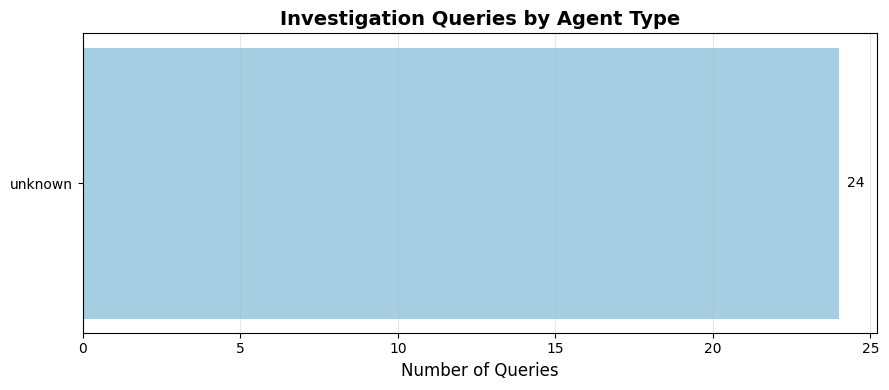

Saved: ../data/figures/queries_per_agent_type.png


In [5]:
agent_counts = q_df['agent_type'].value_counts().sort_values(ascending=True)

fig, ax = plt.subplots(figsize=(9, max(4, len(agent_counts) * 0.7)))
colors = plt.cm.Paired.colors[:len(agent_counts)]
bars = ax.barh(
    agent_counts.index,
    agent_counts.values,
    color=colors[:len(agent_counts)],
    edgecolor='white',
    linewidth=0.7
)
ax.set_xlabel('Number of Queries', fontsize=12)
ax.set_title('Investigation Queries by Agent Type', fontsize=14, fontweight='bold')
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{int(x):,}'))
for bar, val in zip(bars, agent_counts.values):
    ax.text(
        bar.get_width() + max(agent_counts.values) * 0.01,
        bar.get_y() + bar.get_height() / 2,
        f'{val:,}',
        va='center', fontsize=10
    )
ax.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.savefig('../data/figures/queries_per_agent_type.png', dpi=100, bbox_inches='tight')
plt.show()
print('Saved: ../data/figures/queries_per_agent_type.png')

## 5. Query Text Sample (Top-5 by Agent Type)

In [6]:
print('Sample query texts per agent type:\n')
for agent in q_df['agent_type'].unique():
    sample = q_df[q_df['agent_type'] == agent]['query_text'].dropna().head(3).tolist()
    print(f'[{agent}]')
    for i, qt in enumerate(sample, 1):
        print(f'  {i}. {qt}')
    print()

Sample query texts per agent type:

[unknown]
  1. 
  2. 
  3. 



## ✅ Pipeline Status

In [7]:
print('=' * 65)
print('  PIPELINE COMPLETE — No web search performed.')
print('  Queries ready for future agents.')
print('=' * 65)
print()
print(f'  {total_queries:,} queries generated')
print(f'  {total_events:,} unique events covered')
print(f'  {len(agent_types)} agent types ready')
print()
print('Next step: pass investigation_queries.json to a web-search agent')
print('to fetch current pricing intelligence for each flagged event.')

  PIPELINE COMPLETE — No web search performed.
  Queries ready for future agents.

  24 queries generated
  24 unique events covered
  1 agent types ready

Next step: pass investigation_queries.json to a web-search agent
to fetch current pricing intelligence for each flagged event.
